# PW2 · Data processing

## 1 · Configuration
- DATA_DIR : folder containing the participnt folders (i dawnloaded them so you should change it)
- the output folder, window length, sampling rate and maximum tracking gap can be set in the following slot 
- i set PLOT_RECORDING to my personal recording ID but you can choose whichever you prefer

In [ ]:
from pathlib import Path
from tempfile import mkdtemp

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

#DATA_DIR = Path("dataset_classe").expanduser().resolve()
DATA_DIR = Path.home() / "Downloads" / "Data2026pw"
OUTPUT_ROOT = Path("pw2_processed").resolve()
SINGLE_PARTICIPANT = False
#PLOT_RECORDING = None  
PLOT_RECORDING = "Martina/1"

WINDOW_S = 2.0
STEP_S = 0.2
SAMPLE_HZ = 10
MAX_GAP_S = 0.25
RANDOM_SEED = 42

SAMPLES_PER_WINDOW = round(WINDOW_S * SAMPLE_HZ)
if (min(WINDOW_S, STEP_S, SAMPLE_HZ, MAX_GAP_S) <= 0
        or SAMPLES_PER_WINDOW < 1
        or not np.isclose(SAMPLES_PER_WINDOW, WINDOW_S * SAMPLE_HZ)):
    raise ValueError("Use positive parameters and a window duration containing a whole number of samples.")

N_JOINTS = 32
PELVIS = 0
WRISTS = (7, 14)
EVENT_ORDER = ["start", "pointing", "end"]

## 2 · Loading and Validation functions

- Read annotations, remove exact duplicates and sort events by timestamp.
- Require complete, strictly ordered START → POINTING → END triplets.
- Check the 3D format, body ID and timestamp alignment.
- Centre all joints on the pelvis and express time relative to the recording start.
- Identify windows that avoid tracking gaps longer than MAX_GAP_S.

These functions are defined here and called in the next section. Each 3D row must contain a body ID, a timestamp and 96 coordinates (32 joints × 3). Verify that the tracked body is the annotated participant.

In [2]:
def read_gestures(path, video_times):
    events = []
    for line_number, line in enumerate(path.read_text(encoding="utf-8-sig").splitlines(), 1):
        fields = line.split()
        if not fields:
            continue
        if len(fields) != 2 or fields[1].lower() not in EVENT_ORDER:
            raise ValueError(f"Invalid annotation at line {line_number}.")
        timestamp = float(fields[0])
        if not np.isfinite(timestamp):
            raise ValueError(f"Invalid timestamp at line {line_number}.")
        events.append((timestamp, fields[1].lower()))

    unique_events = sorted(set(events))
    timestamps = np.array([t for t, _ in unique_events])
    labels = [label for _, label in unique_events]
    if (not labels or labels != EVENT_ORDER * (len(labels) // 3)
            or np.any(np.diff(timestamps) <= 0)):
        raise ValueError("Check the START / POINTING / END triplet sequence.")
    if not np.isin(timestamps, video_times).all():
        raise ValueError("Some annotations do not match this video's timestamps.")
    return timestamps.reshape(-1, 3), len(events) - len(unique_events)


def load_recording(folder):
    files = sorted(folder.glob("keypoints*.txt"))
    if len(files) != 1:
        raise ValueError(f"Expected one keypoints*.txt file. Files found: {len(files)}.")
    keypoints = files[0]
    tempo_file = folder / keypoints.name.replace("keypoints", "tempos", 1)
    label_file = folder / "visual_analysis.txt"
    if not tempo_file.is_file() or not label_file.is_file():
        missing = [p.name for p in (tempo_file, label_file) if not p.is_file()]
        raise ValueError("Missing files: " + ", ".join(missing))

    clock = np.loadtxt(tempo_file, ndmin=2, encoding="utf-8-sig")
    if clock.shape[1] != 1 or len(clock) < 2:
        raise ValueError("The tempos file must contain one timestamp per row.")
    video_times = clock[:, 0]
    if not np.isfinite(video_times).all() or np.any(np.diff(video_times) <= 0):
        raise ValueError("Video timestamps must be finite and strictly increasing.")

    with keypoints.open(encoding="utf-8-sig") as stream:
        rows = (line for line in stream if line.strip() and line.strip().lower() != "none")
        raw = np.loadtxt(rows, ndmin=2)
    if raw.shape[1] != 2 + N_JOINTS * 3 or len(raw) < 2:
        raise ValueError("Unexpected 3D format. Each row must contain an ID, a timestamp and 96 coordinates.")
    body_ids = np.unique(raw[:, 0])
    if len(body_ids) != 1 or not np.isfinite(body_ids[0]):
        raise ValueError("Multiple or invalid body IDs. Check the annotated participant's track.")
    raw_times = raw[:, 1]
    if not np.isin(raw_times, video_times).all() or np.any(np.diff(raw_times) <= 0):
        raise ValueError("3D timestamps must match the video timestamps and be strictly increasing.")

    gestures, duplicates = read_gestures(label_file, video_times)
    if gestures[0, 0] < raw_times[0] or gestures[-1, 2] > raw_times[-1]:
        raise ValueError("Some gestures fall outside the time range of the 3D track.")

    xyz = raw[:, 2:].reshape(-1, N_JOINTS, 3)
    finite = np.isfinite(xyz).all(axis=(1, 2))
    joint_at_zero = (xyz == 0).all(axis=2).any(axis=1)
    usable = finite & ~joint_at_zero
    if usable.sum() < 2:
        raise ValueError("The track contains fewer than two usable 3D frames.")
    xyz = xyz[usable]
    origin = video_times[0]
    return {
        "time": raw_times[usable] - origin,
        "xyz": xyz,
        "centered": xyz - xyz[:, PELVIS:PELVIS + 1, :],
        "gestures": gestures - origin,
        "body_id": body_ids[0],
        "video_frames": len(video_times),
        "frames_3d": len(raw_times),
        "usable_frames": int(usable.sum()),
        "markers": gestures.size,
        "markers_matching_3d": int(np.isin(gestures, raw_times).sum()),
        "duplicates": duplicates,
    }


def feasible_window_starts(times):
    # Exclude windows that cross a long gap in the 3D track.
    starts = np.arange(times[0], times[-1] - WINDOW_S + 1e-9, STEP_S)
    gaps = np.diff(times) > MAX_GAP_S
    crosses_gap = (
        (starts[:, None] < times[1:][gaps])
        & (starts[:, None] + WINDOW_S > times[:-1][gaps])
    ).any(axis=1)
    return starts[~crosses_gap], int(crosses_gap.sum())

## 3 · Recording checks and participant split

- Find recording folders under DATA_DIR and run the validation functions.
- Flag recordings that need review and keep usable recordings.
- Create a new output directory for this run.
- Split participants into approximately 70% training, 15% validation and 15% test.
- Keep every recording from one participant in the same split.
- Save participant_split.csv. With fewer than three usable participants, assign the demo split.

Coordinates remain in millimetres. The joint indices follow the Azure Kinect joint table.

In [3]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Folder not found: {DATA_DIR}. Set DATA_DIR in the configuration cell.")
folders = sorted({
    path.parent
    for pattern in ("keypoints*.txt", "tempos*.txt", "visual_analysis.txt")
    for path in DATA_DIR.rglob(pattern)
    if path.is_file()
})
if not folders:
    raise FileNotFoundError(f"No recordings found in {DATA_DIR}.")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
run_dir = Path(mkdtemp(prefix="run_", dir=OUTPUT_ROOT))
windows_dir = run_dir / "windows"
windows_dir.mkdir()
report = []
recordings = []

for folder in folders:
    relative = folder.relative_to(DATA_DIR)
    participant = "P01" if SINGLE_PARTICIPANT else (relative.parts or ("",))[0]
    row = {"participant_id": participant, "recording_id": relative.as_posix()}
    report.append(row)
    try:
        if not participant:
            raise ValueError("Place the recording inside its participant folder.")
        recording = load_recording(folder)
        for field in ("body_id", "video_frames", "frames_3d", "usable_frames",
                      "markers", "markers_matching_3d", "duplicates"):
            row[field] = recording[field]
        starts, gap_count = feasible_window_starts(recording["time"])
        row["gestures"] = len(recording["gestures"])
        row["windows_crossing_gaps"] = gap_count
        if not len(starts):
            raise ValueError("No usable windows with the current duration and gap threshold.")
    except (ValueError, OSError) as error:
        row.update(status="needs_review", reason=str(error))
        continue
    row.update(status="ok", reason="")
    recordings.append((row, recording, starts))

participants = sorted({row["participant_id"] for row, _, _ in recordings})
if not participants:
    pd.DataFrame(report).to_csv(run_dir / "quality_report.csv", index=False)
    raise ValueError(f"No recordings could be processed. Check {run_dir / 'quality_report.csv'}.")

shuffled = np.random.default_rng(RANDOM_SEED).permutation(participants).tolist()
if len(shuffled) < 3:
    splits = dict.fromkeys(shuffled, "demo")
else:
    held_out = max(1, round(0.15 * len(shuffled)))
    splits = dict.fromkeys(shuffled, "train")
    splits.update(dict.fromkeys(shuffled[-2 * held_out:-held_out], "validation"))
    splits.update(dict.fromkeys(shuffled[-held_out:], "test"))
participant_split = pd.DataFrame([
    {"participant_id": participant, "split": splits[participant]} for participant in participants
])
participant_split.to_csv(run_dir / "participant_split.csv", index=False)

4 · Window generation and dataset export
- Interpolate centred coordinates onto a regular time grid.
- Assign label 1 when the window centre falls inside a START–END interval.
- Assign label 0 when the centre falls outside all annotated gestures.
- Save overlaps_gesture to identify windows that include any part of a gesture.
- Export one NPZ per recording, quality_report.csv and gestures.csv.
- Display participant, recording, gesture and window counts for each split.

X has shape (windows, SAMPLES_PER_WINDOW, 32, 3). With the default settings, each window has 20 samples. Select fully background windows with (y == 0) & (~overlaps_gesture). POINTING is one annotated instant within each gesture.

In [4]:
def make_windows(recording, starts):
    grid = starts[:, None] + np.arange(SAMPLES_PER_WINDOW) / SAMPLE_HZ
    time = recording["time"]
    flat_coordinates = recording["centered"].reshape(len(time), -1)
    flat_windows = np.column_stack([
        np.interp(grid.ravel(), time, channel) for channel in flat_coordinates.T
    ])
    X = flat_windows.reshape(len(starts), SAMPLES_PER_WINDOW, N_JOINTS, 3).astype(np.float32)

    centers = starts + WINDOW_S / 2
    gesture_start, _, gesture_end = recording["gestures"].T
    centered_on_gesture = (
        (gesture_start <= centers[:, None]) & (centers[:, None] <= gesture_end)
    ).any(axis=1)
    overlaps_gesture = (
        (starts[:, None] <= gesture_end) & (gesture_start < starts[:, None] + WINDOW_S)
    ).any(axis=1)
    return X, centered_on_gesture.astype(np.uint8), centers, overlaps_gesture


gesture_rows = []
for index, (row, recording, starts) in enumerate(recordings, 1):
    X, y, centers, overlaps = make_windows(recording, starts)
    path = windows_dir / f"recording_{index:04d}.npz"
    split = splits[row["participant_id"]]
    np.savez_compressed(
        path, X=X, y=y, overlaps_gesture=overlaps,
        window_start_s=starts, window_center_s=centers,
        participant_id=row["participant_id"], recording_id=row["recording_id"],
        split=split,
    )
    row.update(
        split=split, window_file=path.relative_to(run_dir).as_posix(), windows=len(y),
        positive=int(y.sum()), background_clear=int(((y == 0) & ~overlaps).sum()),
        background_with_overlap=int(((y == 0) & overlaps).sum()),
    )
    for gesture_id, (start, pointing, end) in enumerate(recording["gestures"], 1):
        gesture_rows.append({
            "participant_id": row["participant_id"], "recording_id": row["recording_id"],
            "split": split, "gesture_id": gesture_id, "start_s": start, "pointing_s": pointing,
            "end_s": end, "duration_s": end - start, "start_to_pointing_s": pointing - start,
        })

quality = pd.DataFrame(report)
quality.fillna("").to_csv(run_dir / "quality_report.csv", index=False)
pd.DataFrame(gesture_rows).to_csv(run_dir / "gestures.csv", index=False, float_format="%.6f")
processed = quality.loc[quality["status"].eq("ok")]
summary = processed.groupby("split").agg(
    participants=("participant_id", "nunique"), recordings=("recording_id", "size"),
    gestures=("gestures", "sum"), windows=("windows", "sum"), positive=("positive", "sum"),
    background_clear=("background_clear", "sum"),
    background_with_overlap=("background_with_overlap", "sum"),
).astype(int)
summary = summary.loc[[key for key in ("train", "validation", "test", "demo") if key in summary.index]]
print(f"Processed recordings: {len(processed)}/{len(quality)}")
print(f"Usable participants: {len(participants)}")
print(f"Results: {run_dir}")
display(summary)
if len(processed) < len(quality):
    display(quality.loc[quality["status"].eq("needs_review"), ["recording_id", "reason"]])

Processed recordings: 35/66
Usable participants: 15
Results: /Users/marti/Downloads/Martina/pw2_processed/run_7ihp90ub


,participants,recordings,gestures,windows,positive,background_clear,background_with_overlap
split,,,,,,,
train,11,25,614,10227,6101,1103,3023
validation,2,6,163,1613,991,111,511
test,2,4,99,1621,888,239,494


,recording_id,reason
0,Ada/1,Check the START / POINTING / END triplet seque...
1,Ada/2,Check the START / POINTING / END triplet seque...
2,Ada/3,Check the START / POINTING / END triplet seque...
3,Alessandro/1,Missing files: visual_analysis.txt
4,Alessandro/2,Missing files: visual_analysis.txt
5,Alessandro/3,Missing files: visual_analysis.txt
7,Ali/2,Check the START / POINTING / END triplet seque...
8,Ali/3,Multiple or invalid body IDs. Check the annota...
15,Andrea/1,Missing files: visual_analysis.txt
16,Andrea/2,Missing files: visual_analysis.txt


5 · Gesture duration statistics
- Calculate duration as END − START for every processed gesture.
- Report mean, median, sample variance, sample standard deviation, quartiles and range.
- Count gestures longer than WINDOW_S.
- Plot a histogram with 0.25 s bins and a reference line at WINDOW_S.
- Save gesture_duration_statistics.csv and gesture_duration_histogram.png.

Variance is measured in s². Standard deviation is measured in s. Q1–Q3 contains the middle 50% of durations.

,Value
gestures,876.000
mean_s,2.099
median_s,1.934
sample_variance_s2,0.612
sample_sd_s,0.782
q1_s,1.580
q3_s,2.406
min_s,0.686
max_s,9.233
window_s,2.000


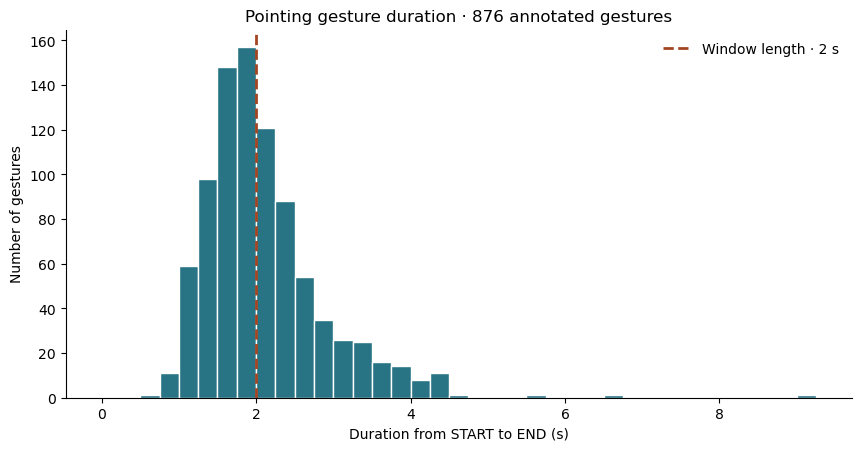

In [5]:
durations = pd.DataFrame(gesture_rows)["duration_s"]
long_gestures = int(durations.gt(WINDOW_S).sum())

duration_stats = pd.DataFrame([{
    "gestures": len(durations),
    "mean_s": durations.mean(),
    "median_s": durations.median(),
    "sample_variance_s2": durations.var(ddof=1),
    "sample_sd_s": durations.std(ddof=1),
    "q1_s": durations.quantile(0.25),
    "q3_s": durations.quantile(0.75),
    "min_s": durations.min(),
    "max_s": durations.max(),
    "window_s": WINDOW_S,
    "longer_than_window": long_gestures,
    "longer_than_window_pct": 100 * long_gestures / len(durations),
}])
duration_stats.to_csv(run_dir / "gesture_duration_statistics.csv", index=False)
display(duration_stats.T.rename(columns={0: "Value"}).round(3))

bin_width_s = 0.25
last_edge = np.ceil(durations.max() / bin_width_s) * bin_width_s
bins = np.arange(0, last_edge + bin_width_s, bin_width_s)
fig, ax = plt.subplots(figsize=(8.5, 4.4), layout="constrained")
ax.hist(durations, bins=bins, color="#287485", edgecolor="white")
ax.axvline(WINDOW_S, color="#a34522", ls="--", lw=2, label=f"Window length · {WINDOW_S:g} s")
ax.set(
    title=f"Pointing gesture duration · {len(durations)} annotated gestures",
    xlabel="Duration from START to END (s)",
    ylabel="Number of gestures",
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig(run_dir / "gesture_duration_histogram.png", dpi=220)
plt.show()


6 · Participant statistics
- Count usable recordings and gestures for each participant.
- Calculate median gesture duration and median START-to-POINTING time.
- Sort participants by gesture count.
- Display the table and save participant_gesture_statistics.csv.

In [6]:
gestures_df = pd.DataFrame(gesture_rows)

participant_stats = (
    gestures_df.groupby(["participant_id", "split"], as_index=False)
    .agg(
        n_recordings=("recording_id", "nunique"),
        n_gestures=("duration_s", "size"),
        median_duration_s=("duration_s", "median"),
        median_start_to_pointing_s=("start_to_pointing_s", "median"),
    )
    .sort_values("n_gestures", ascending=False)
    .reset_index(drop=True)
)

display(participant_stats.round(2))
participant_stats.to_csv(
    run_dir / "participant_gesture_statistics.csv",
    index=False,
)

,participant_id,split,n_recordings,n_gestures,median_duration_s,median_start_to_pointing_s
0,Sara,validation,3,84,1.23,0.63
1,Shaghayegh,test,3,81,1.64,0.54
2,Aliakbar,validation,3,79,1.82,0.97
3,Martina,train,3,78,2.75,0.92
4,Greta,train,3,78,3.61,1.53
5,Francesco,train,3,78,1.78,0.63
6,Giulia,train,3,78,2.29,0.88
7,Amirhossein,train,3,77,1.84,0.73
8,Mustafa,train,2,60,1.86,0.90
9,Sule,train,2,56,1.86,0.93


## 7 · Visual comparison across recordings

- Generate one plot for every successfully processed recording.
- Show the first annotated gesture and automatically select the wrist with the largest START-to-POINTING displacement.
- Use seconds relative to START and shared vertical scales across all recordings.
- Save individual PNG files and a multipage comparison PDF under wrist_plots.
- Display overview pages with up to six recordings each.

Each overview row shows camera and pelvis-centred coordinates for the same recording. Only recordings that passed the earlier checks appear. Wrist selection is automatic and should be checked against the video when tracking looks unusual.


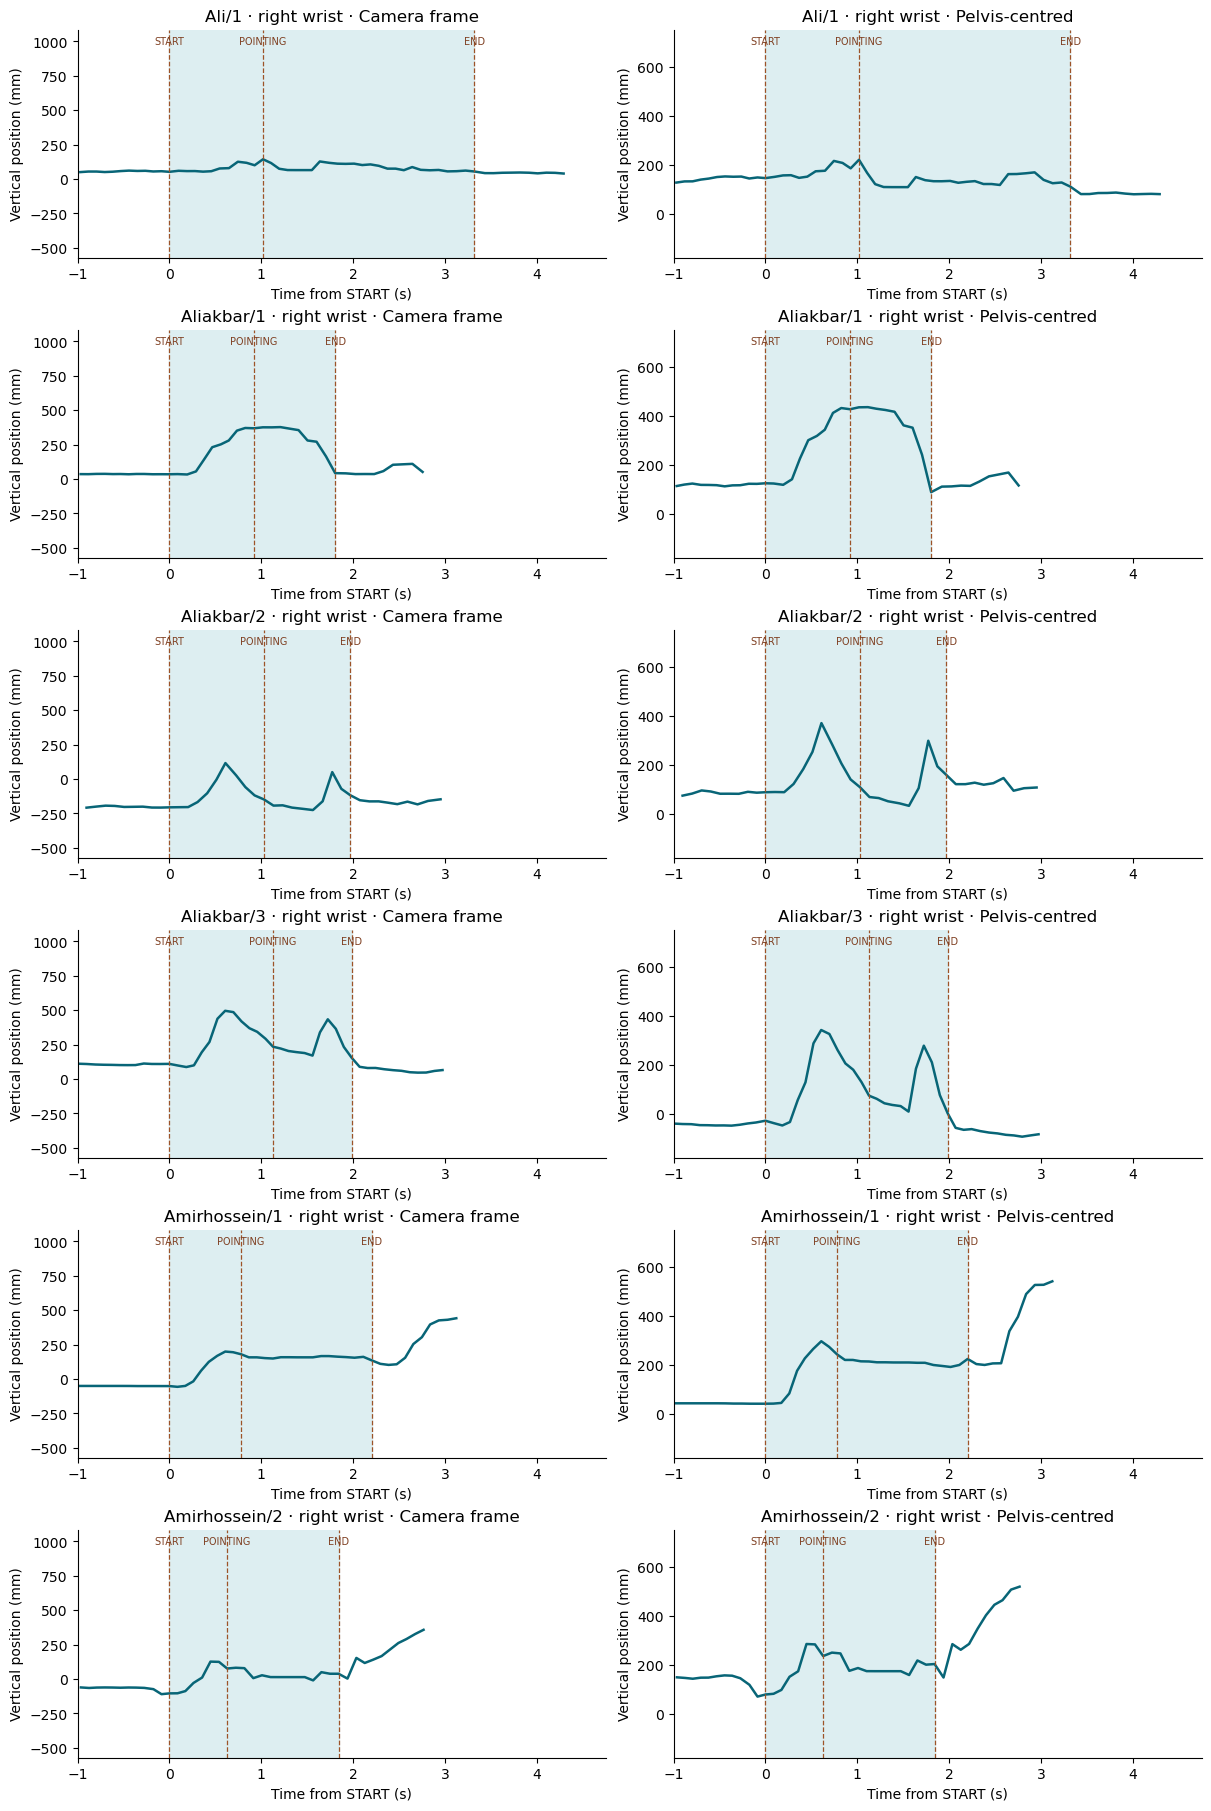

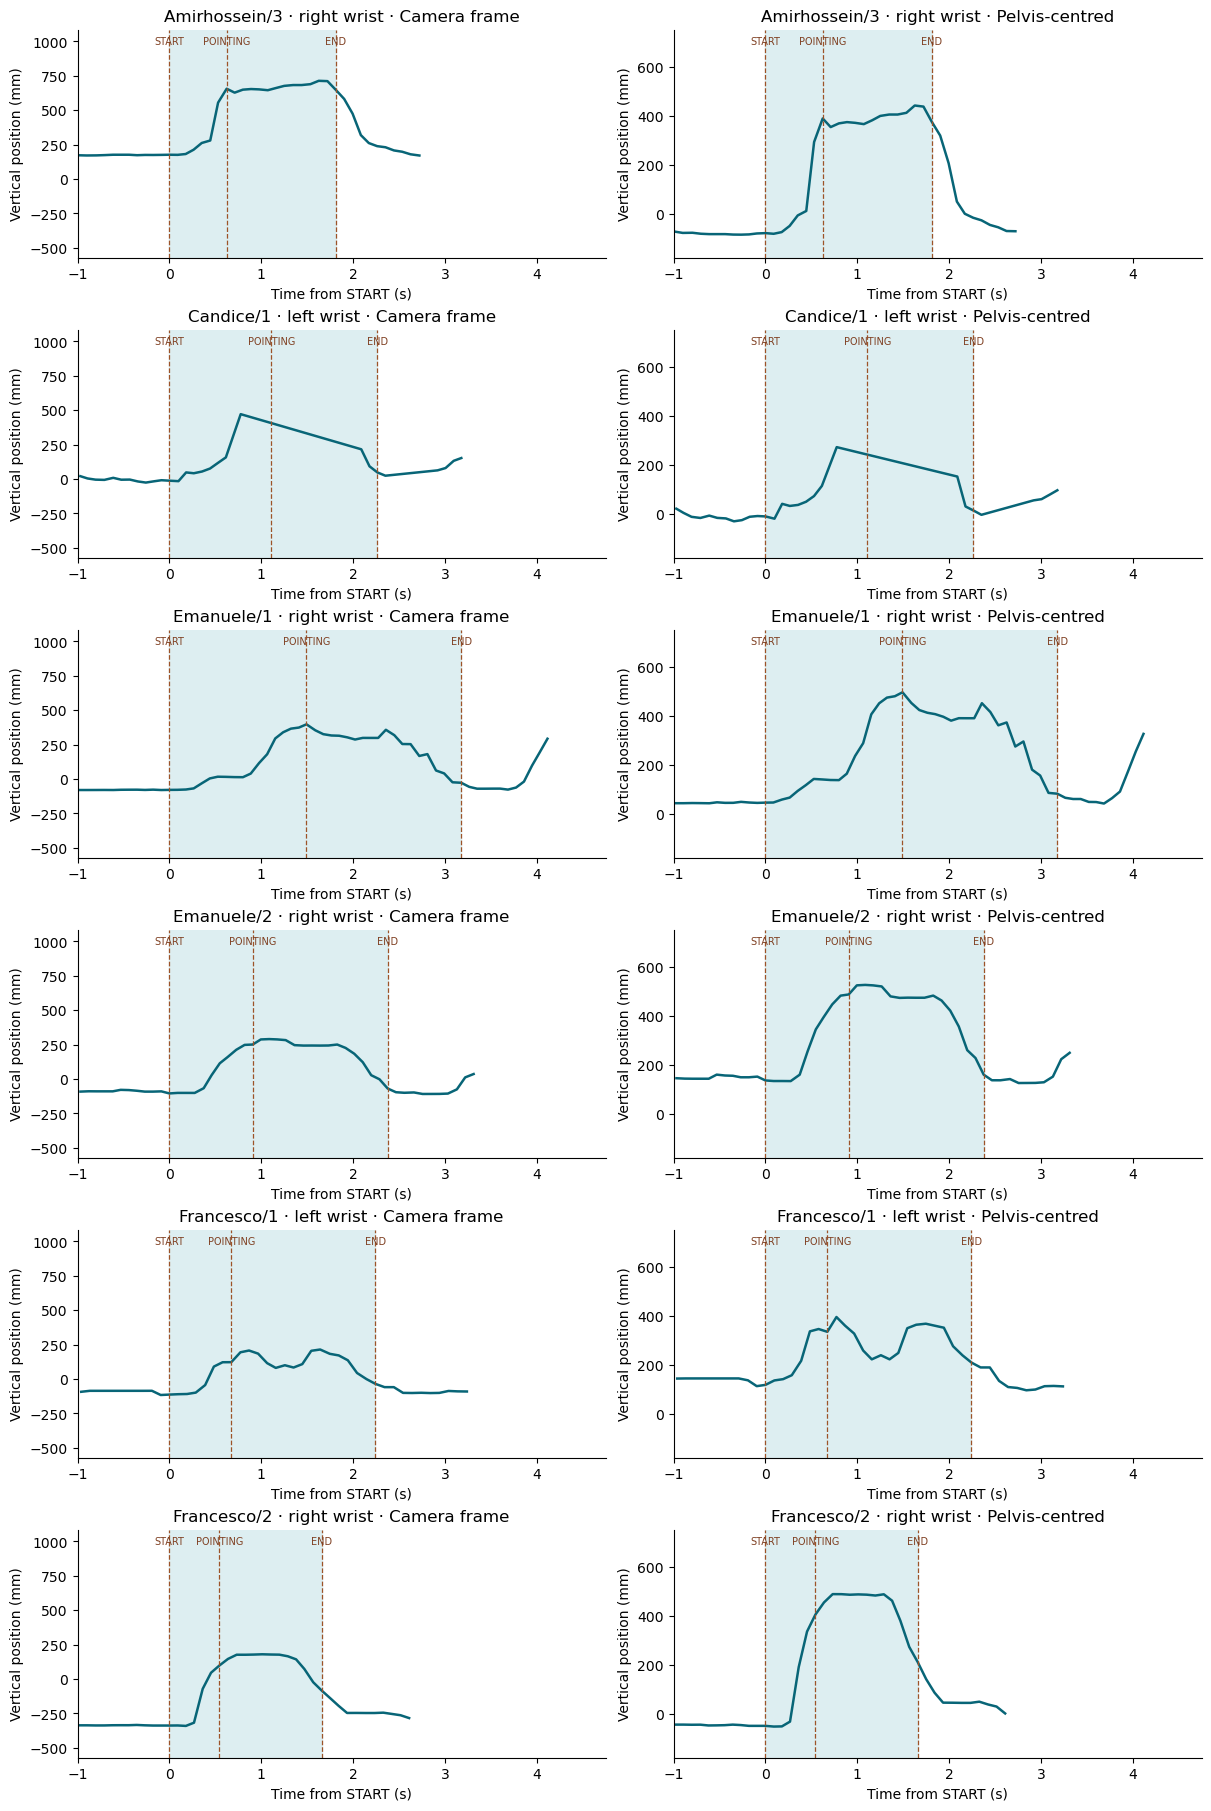

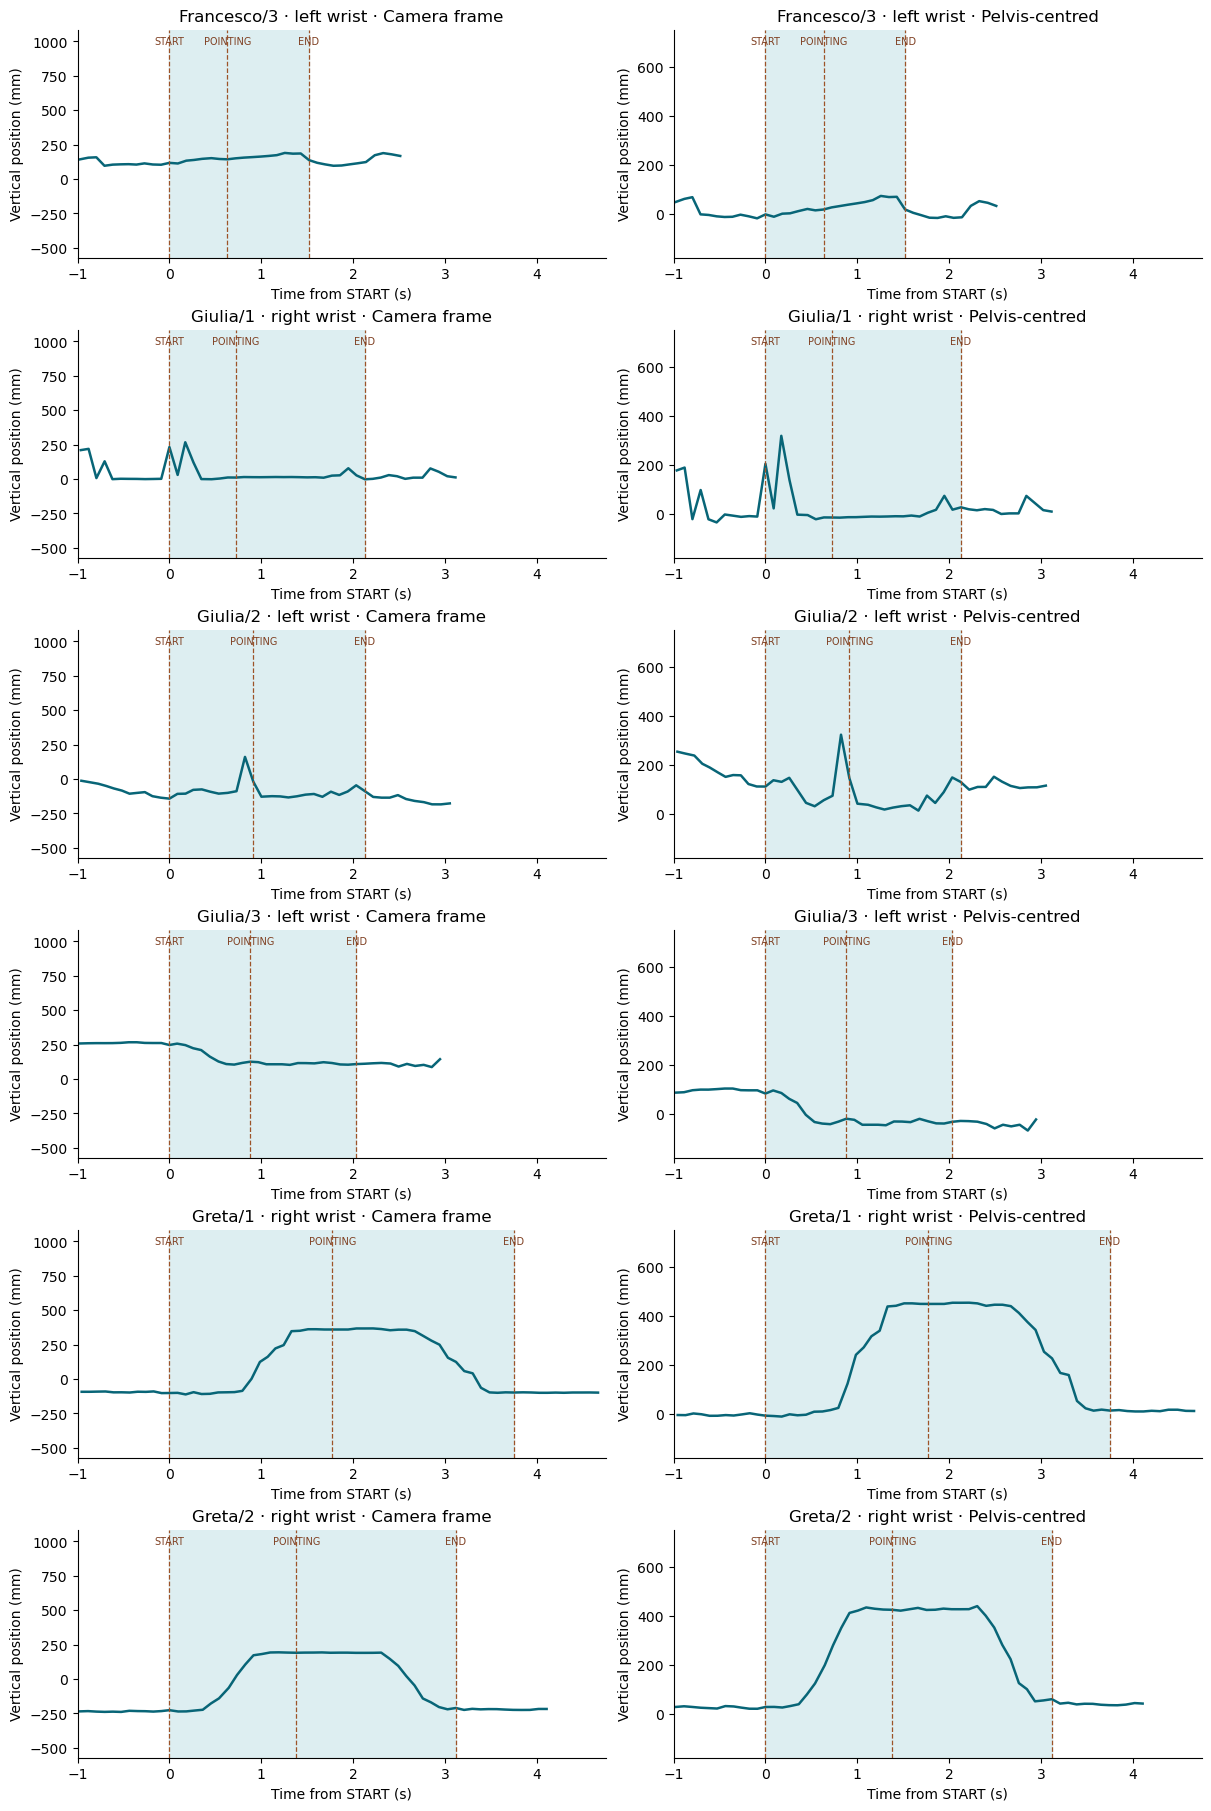

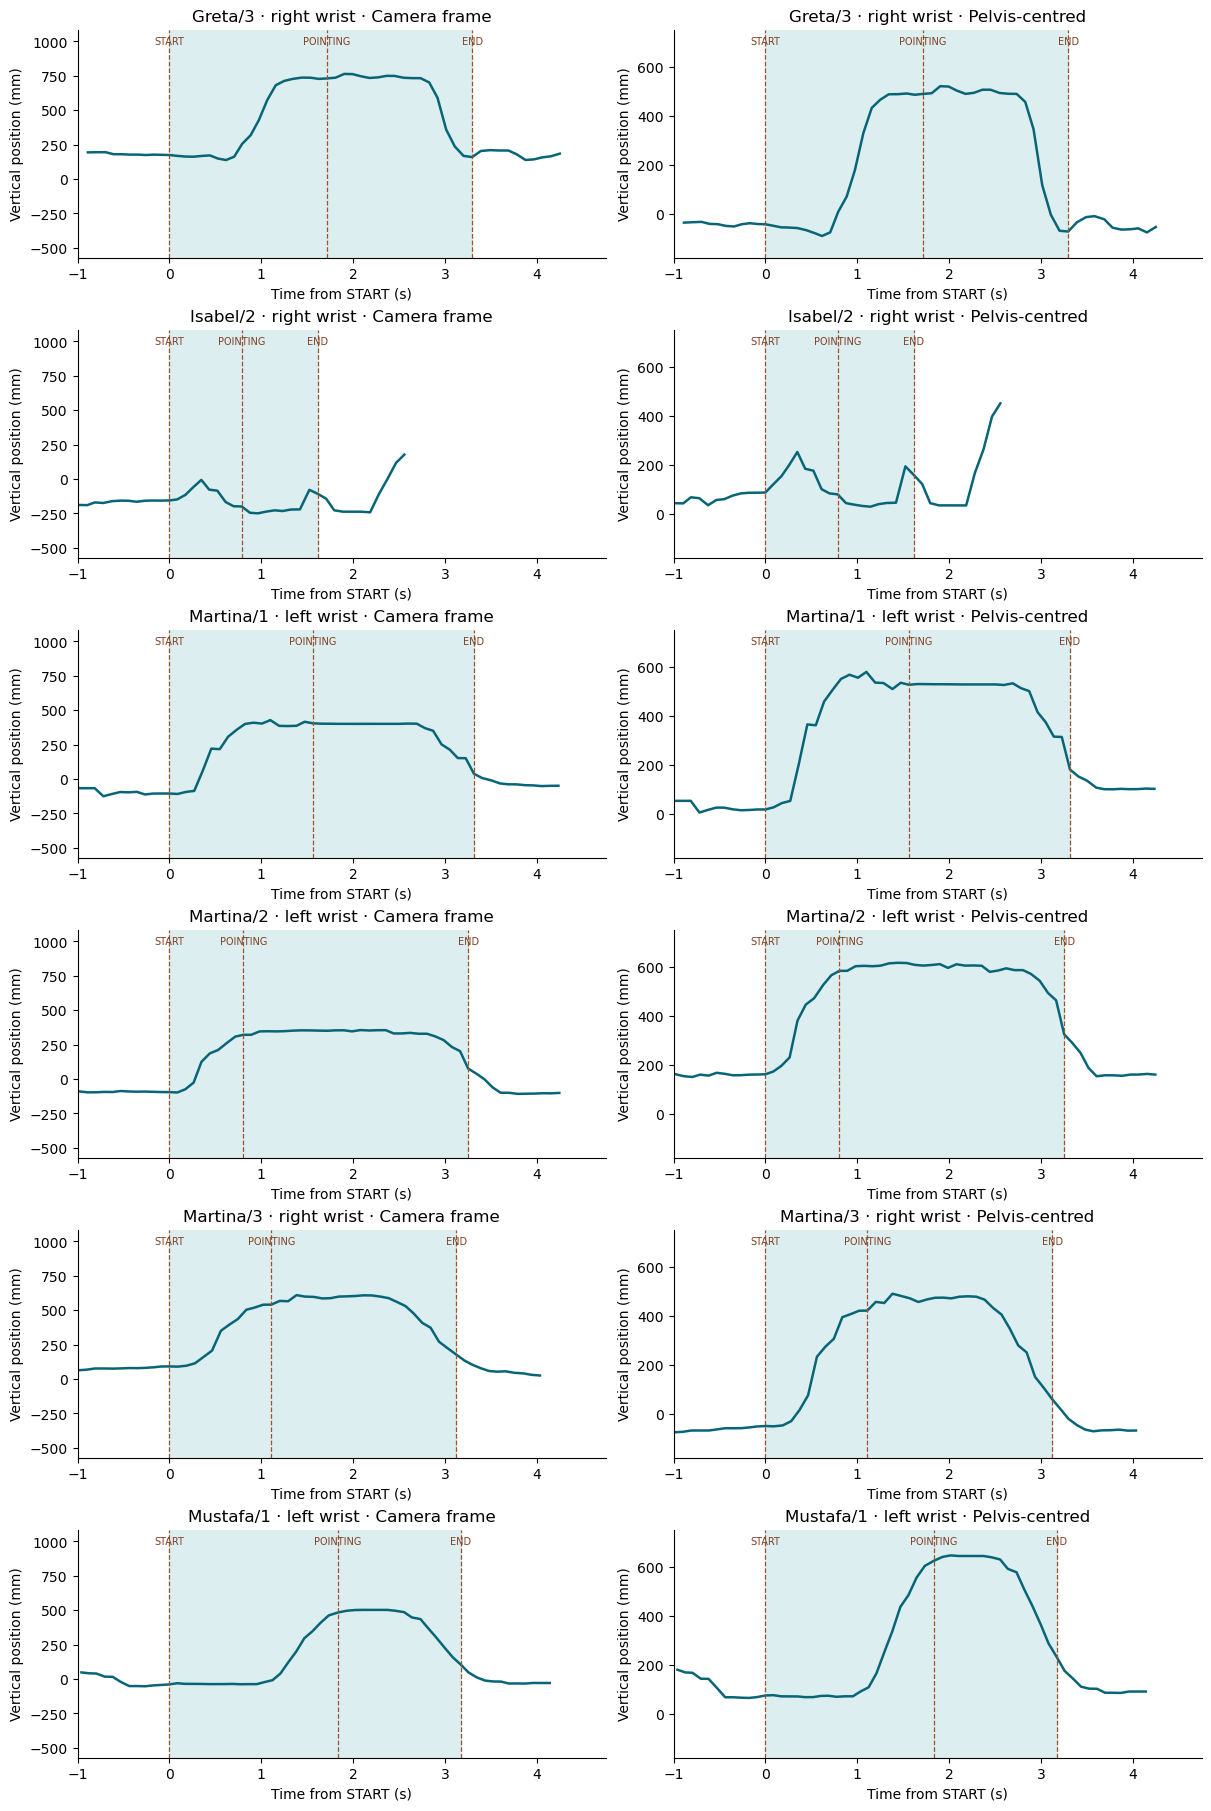

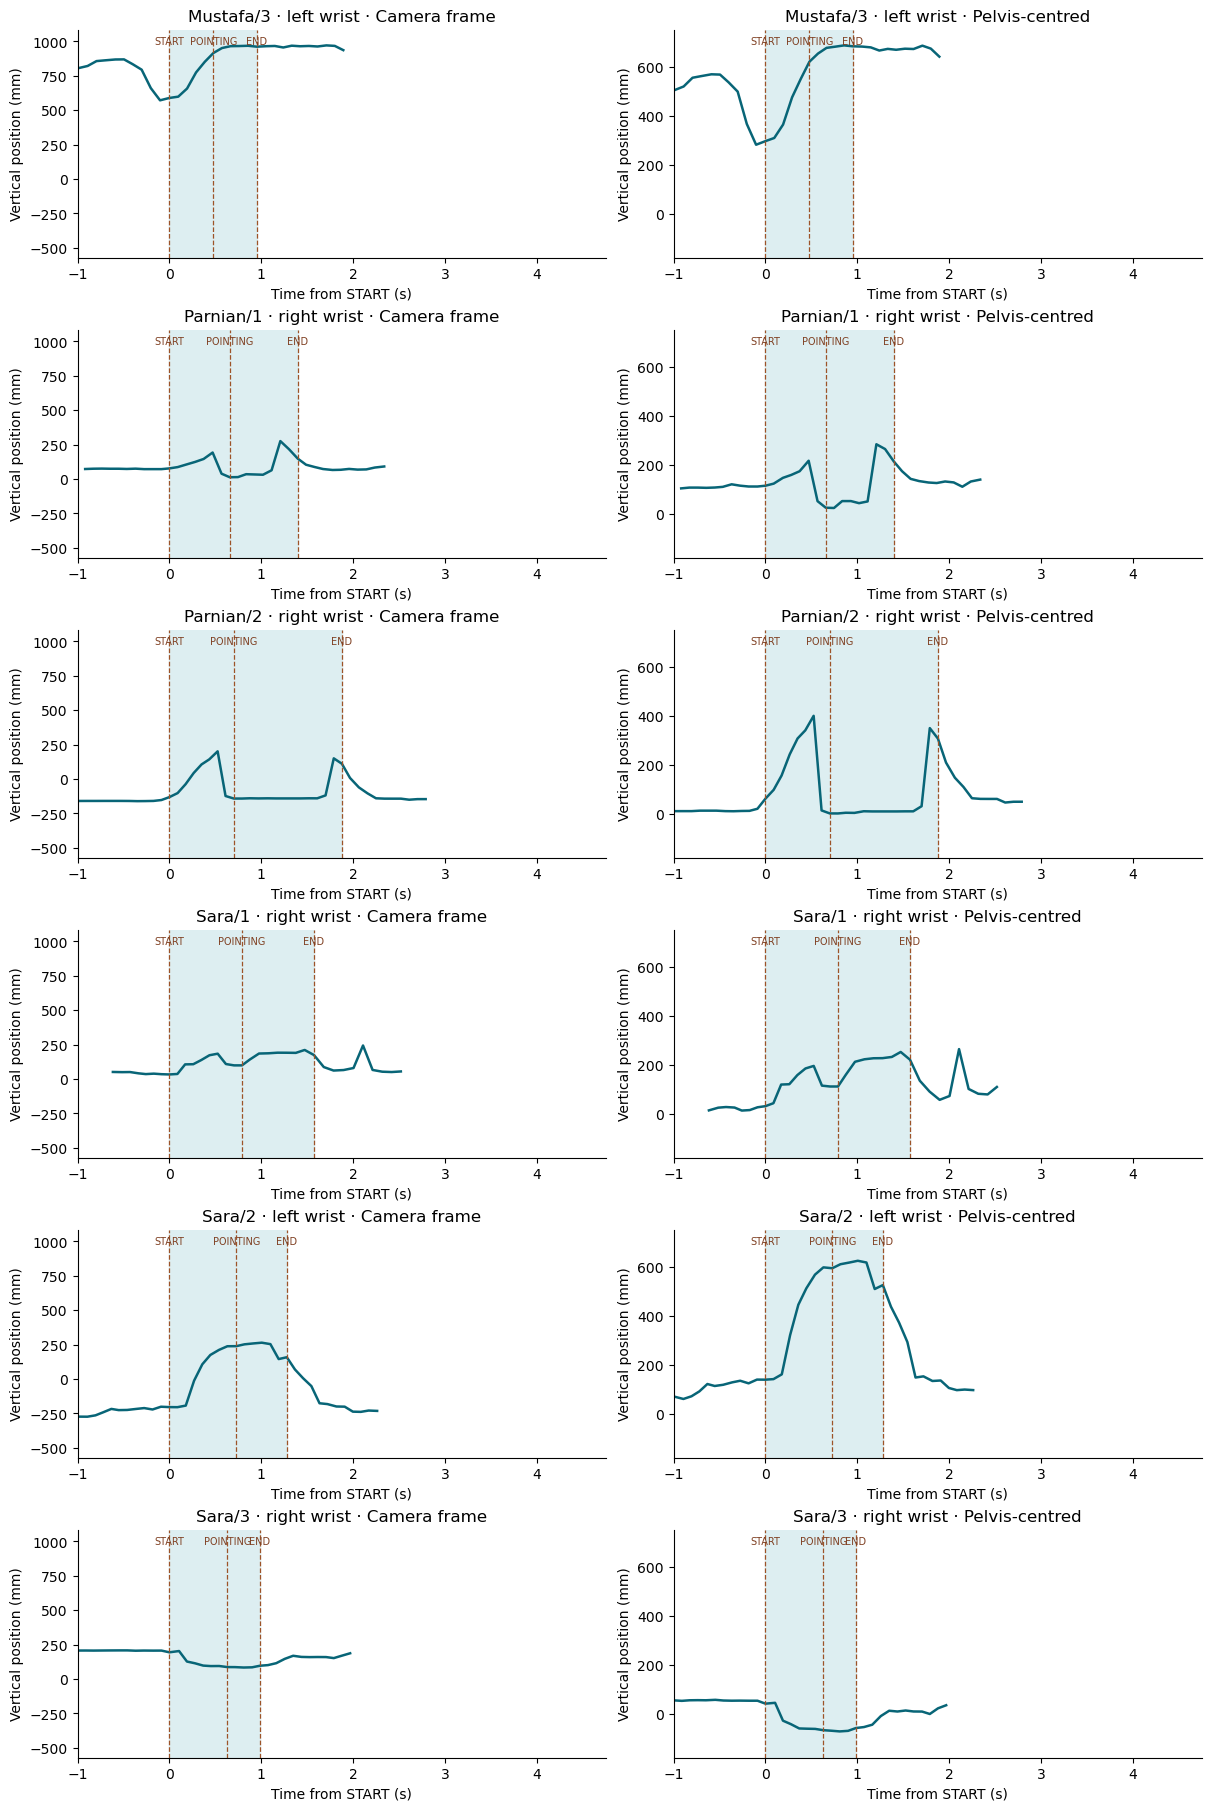

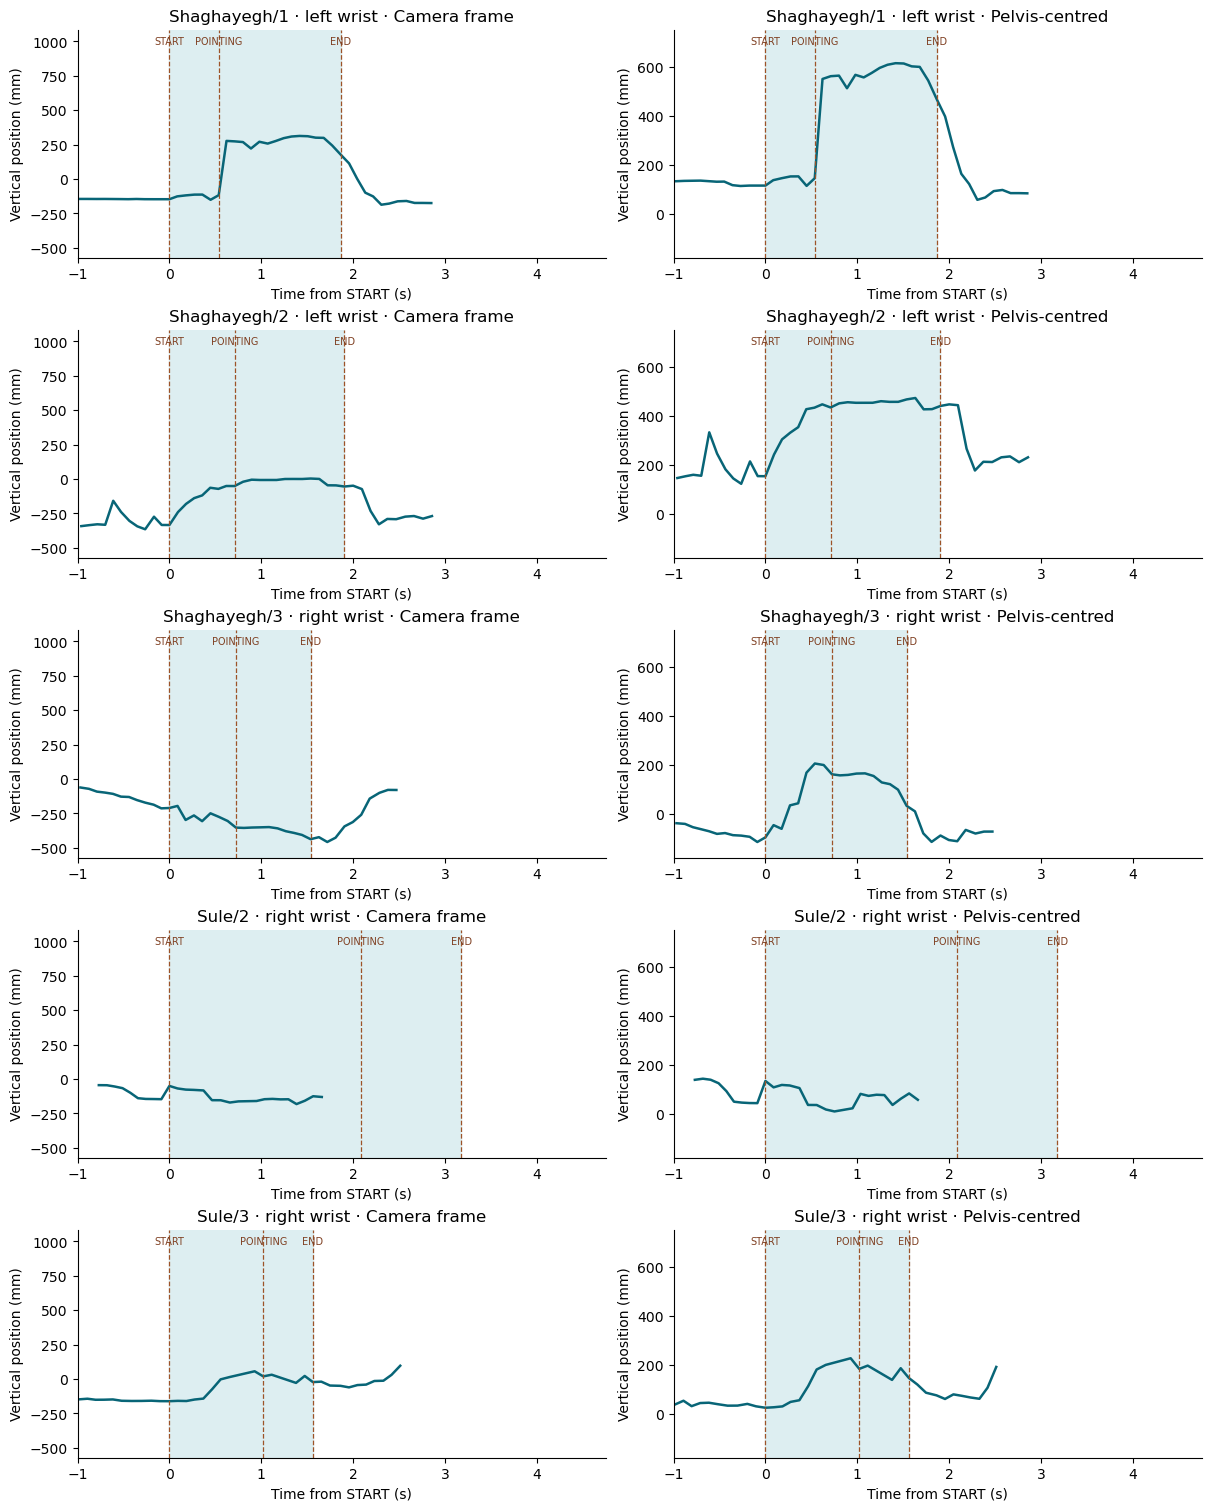

Generated 35 recording plots.
Files saved to /Users/marti/Downloads/Martina/pw2_processed/run_7ihp90ub/wrist_plots


/Users/marti/Downloads/Martina/pw2_processed/run_7ihp90ub/wrist_plots/all_recordings_comparison.pdf

In [7]:
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import FileLink

plot_dir = run_dir / "wrist_plots"
plot_dir.mkdir(exist_ok=True)
plot_examples = []

for metadata, recording, _ in recordings:
    start, pointing, end = recording["gestures"][0]
    time = recording["time"]
    indices = np.abs(time[:, None] - np.array([start, pointing])).argmin(axis=0)
    displacement = (
        recording["centered"][indices[1], WRISTS, :]
        - recording["centered"][indices[0], WRISTS, :]
    )
    wrist = WRISTS[int(np.linalg.norm(displacement, axis=1).argmax())]
    view = (time >= start - 1) & (time <= end + 1)
    plot_examples.append({
        "recording_id": metadata["recording_id"],
        "time": time[view] - start,
        "camera": -recording["xyz"][view, wrist, 1],
        "centered": -recording["centered"][view, wrist, 1],
        "pointing": pointing - start,
        "end": end - start,
        "side": "left" if wrist == WRISTS[0] else "right",
    })

# Use one vertical scale per coordinate system across the whole comparison.
plot_limits = {}
for coordinate in ("camera", "centered"):
    values = np.concatenate([example[coordinate] for example in plot_examples])
    low, high = values.min(), values.max()
    margin = max((high - low) * 0.08, 10)
    plot_limits[coordinate] = (low - margin, high + margin)
time_limits = (-1, max(example["end"] for example in plot_examples) + 1)


def draw_wrist_pair(axes, example):
    for ax, coordinate, title in zip(
        axes, ("camera", "centered"), ("Camera frame", "Pelvis-centred")
    ):
        ax.axvspan(0, example["end"], color="#ddeef1")
        ax.plot(example["time"], example[coordinate], color="#086577", lw=1.8)
        for instant, label in zip(
            (0, example["pointing"], example["end"]), EVENT_ORDER
        ):
            ax.axvline(instant, ls="--", color="#9d5328", lw=0.9)
            ax.text(
                instant, 0.97, label.upper(),
                transform=ax.get_xaxis_transform(), ha="center", va="top",
                fontsize=7, color="#7f3f21",
            )
        ax.set(
            title=f'{example["recording_id"]} · {example["side"]} wrist · {title}',
            xlabel="Time from START (s)", ylabel="Vertical position (mm)",
            xlim=time_limits, ylim=plot_limits[coordinate],
        )
        ax.spines[["right", "top"]].set_visible(False)


for index, example in enumerate(plot_examples, 1):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
    draw_wrist_pair(axes, example)
    fig.savefig(plot_dir / f"recording_{index:04d}.png", dpi=170)
    plt.close(fig)

# A manifest links each filename to its participant and recording.
pd.DataFrame([
    {
        "recording_id": example["recording_id"],
        "selected_wrist": example["side"],
        "plot_file": f"recording_{index:04d}.png",
    }
    for index, example in enumerate(plot_examples, 1)
]).to_csv(plot_dir / "plot_index.csv", index=False)

pdf_path = plot_dir / "all_recordings_comparison.pdf"
with PdfPages(pdf_path) as pdf:
    for offset in range(0, len(plot_examples), 6):
        page = plot_examples[offset:offset + 6]
        fig, axes = plt.subplots(
            len(page), 2, figsize=(12, 3 * len(page)),
            squeeze=False, layout="constrained",
        )
        for row_axes, example in zip(axes, page):
            draw_wrist_pair(row_axes, example)
        pdf.savefig(fig)
        display(fig)
        plt.close(fig)

print(f"Generated {len(plot_examples)} recording plots.")
print(f"Files saved to {plot_dir}")
display(FileLink(str(pdf_path)))
